=== Shape ===
Original (Skin only): (836, 21)
Extended:             (3836, 20)

=== Risk Level Distribution (proportions) ===
Original (Skin only):
Risk_Level
Medium    0.787
Low       0.177
High      0.036
Name: proportion, dtype: float64

Extended:
Risk_Level
Medium    0.792
Low       0.175
High      0.033
Name: proportion, dtype: float64

Comparing 18 features

=== Statistical Comparison ===
Feature                    Orig Mean   Ext Mean    Orig SD     Ext SD
----------------------------------------------------------------------
Age                           63.026     62.959     10.251     10.770
Gender                         0.642      0.626      0.480      0.484
Smoking                        4.195      4.274      2.909      2.890
Alcohol_Use                    4.876      4.865      3.171      3.170
Obesity                        5.502      5.480      2.957      3.013
Family_History                 0.171      0.162      0.377      0.368
Diet_Red_Meat                  4.523     

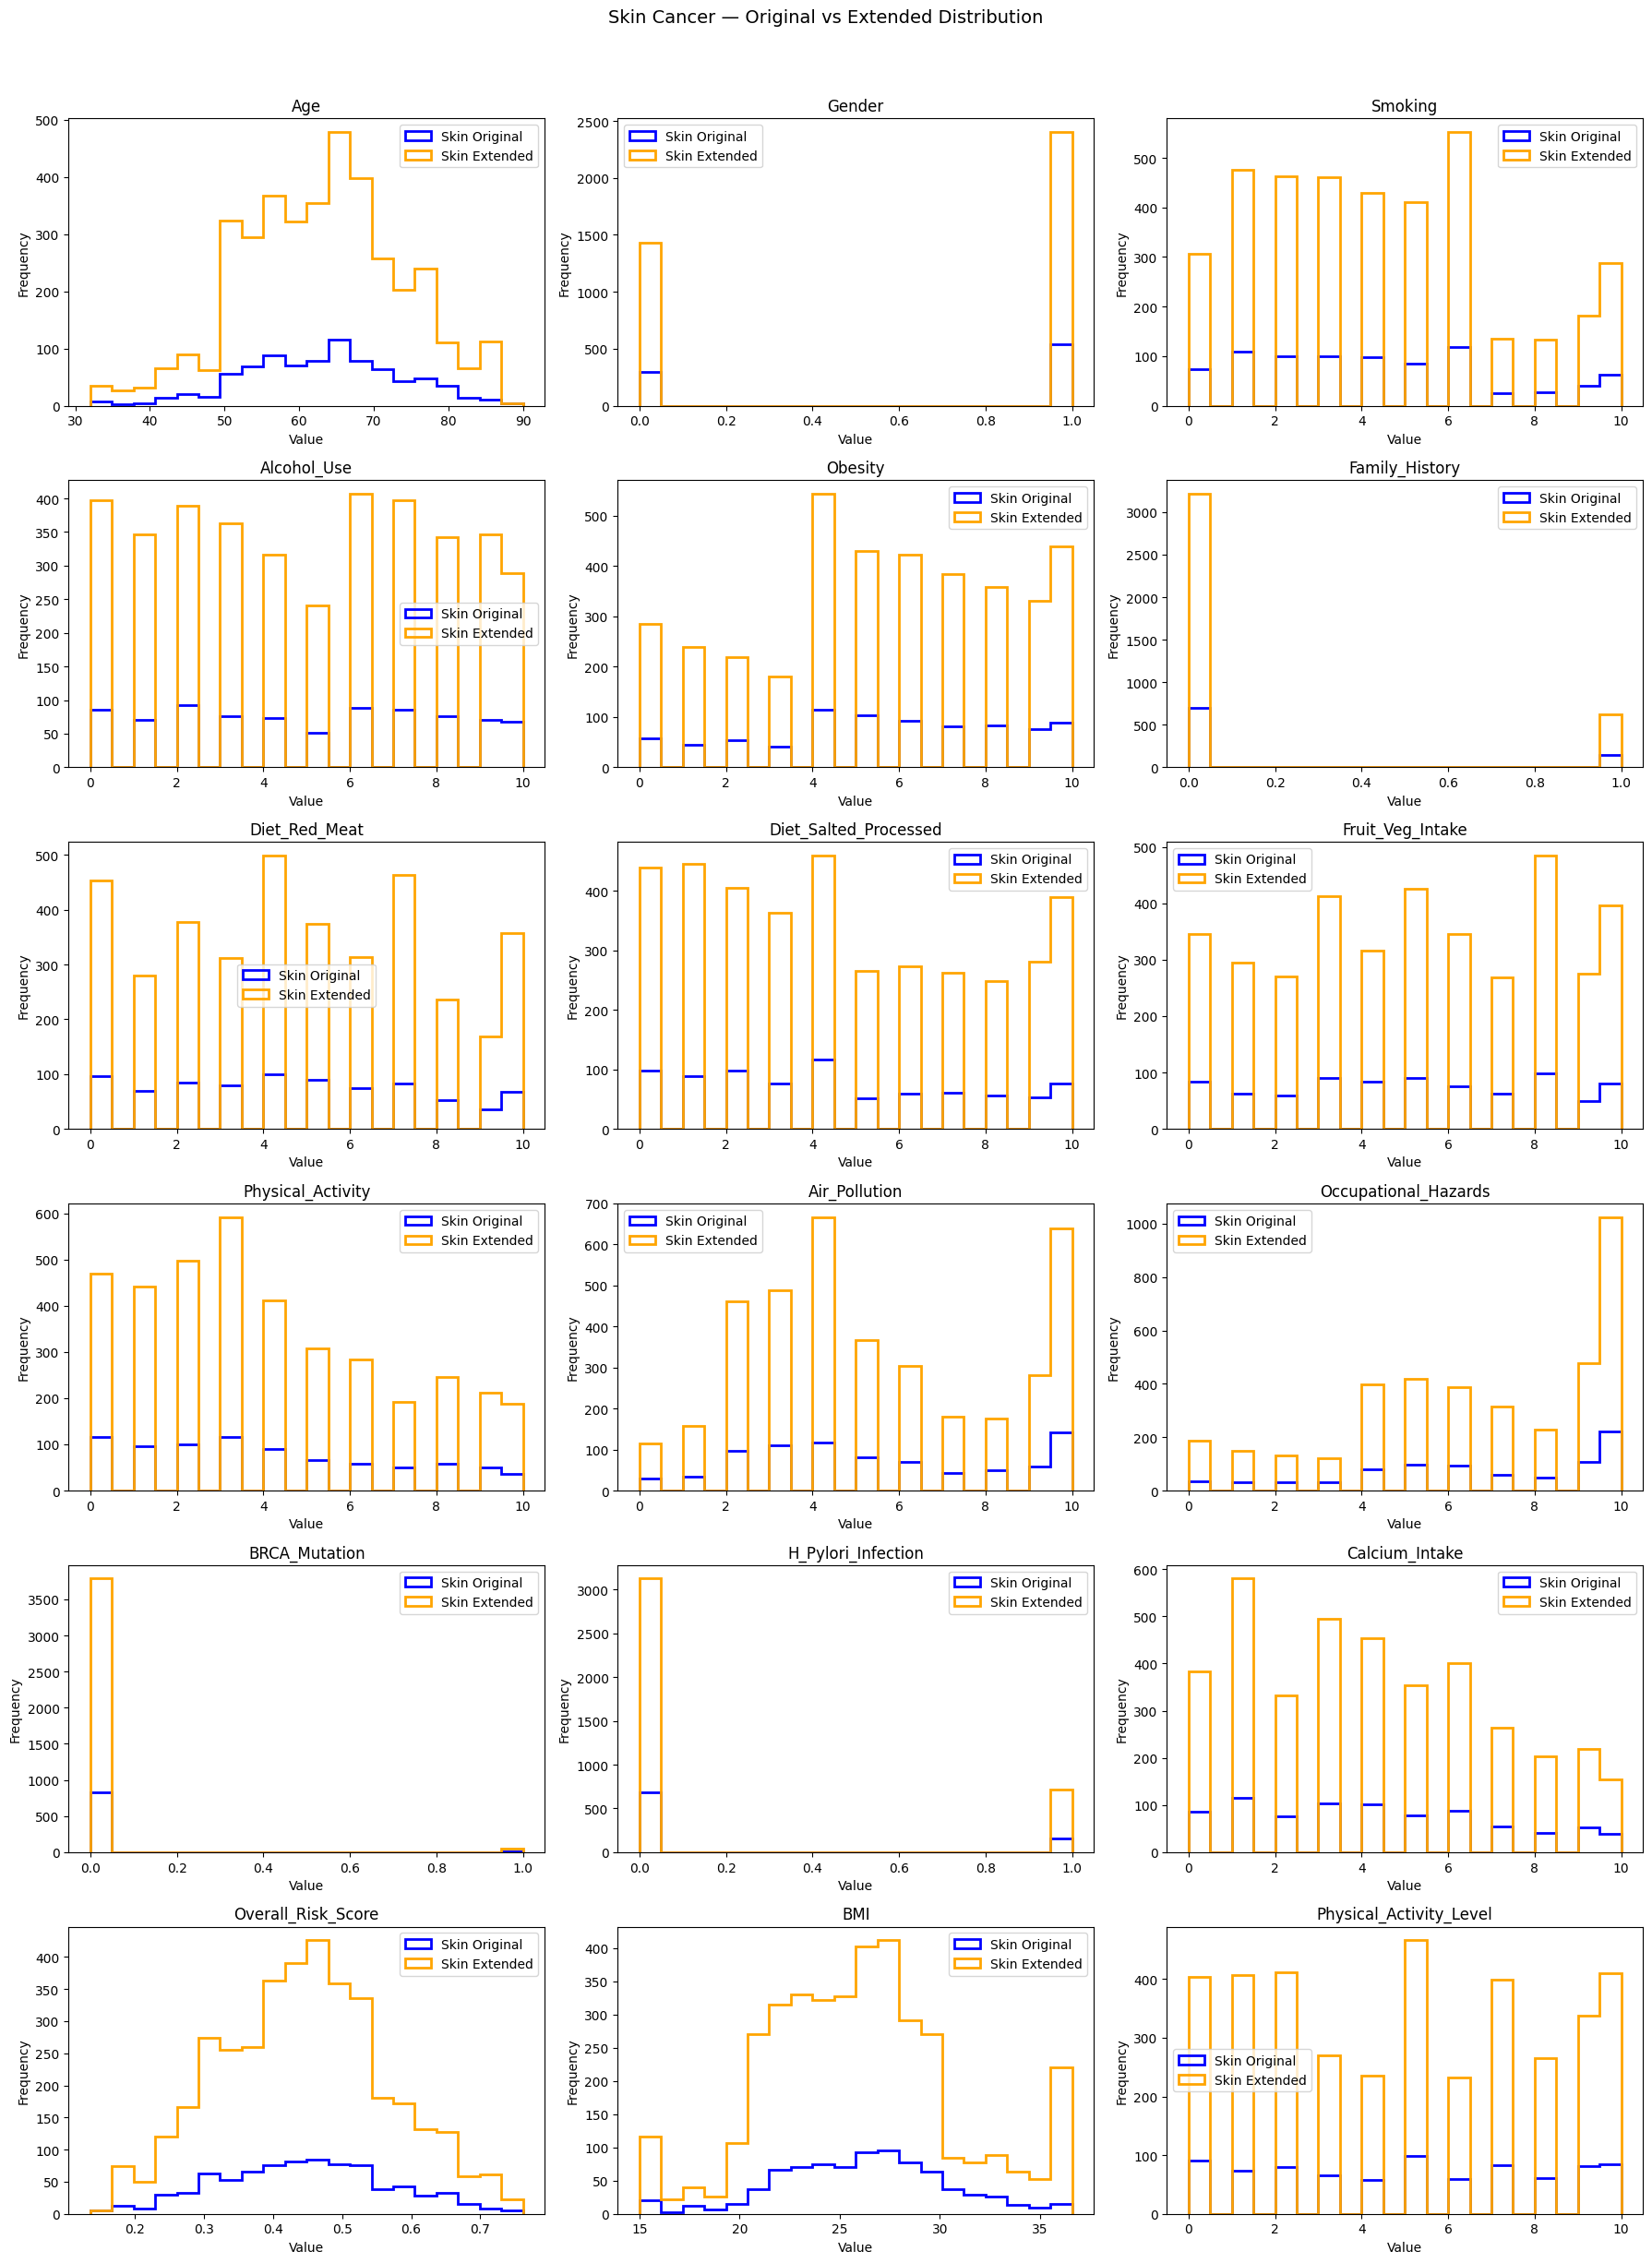

Saved Skin_comparison.png


In [2]:
# Visual Representation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

# Load both
df_full = pd.read_csv("cancer-risk-factors-extended-1.csv")
df_skin_extended = pd.read_csv("skin_cancer_extended.csv")

# Filter original to Skin only
df_original = df_full[df_full["Cancer_Type"] == "Skin"].copy()

print("=== Shape ===")
print(f"Original (Skin only): {df_original.shape}")
print(f"Extended:             {df_skin_extended.shape}")

# Risk Level
print("\n=== Risk Level Distribution (proportions) ===")
print("Original (Skin only):")
print(df_original["Risk_Level"].value_counts(normalize=True).round(3))
print("\nExtended:")
print(df_skin_extended["Risk_Level"].value_counts(normalize=True).round(3))

# Auto-detect numeric columns
exclude  = ["Patient_ID", "Cancer_Type", "Risk_Level"]
num_cols = [col for col in df_skin_extended.columns
            if col not in exclude]

print(f"\nComparing {len(num_cols)} features")

# Statistical comparison
print("\n=== Statistical Comparison ===")
print(f"{'Feature':<25} {'Orig Mean':>10} {'Ext Mean':>10} {'Orig SD':>10} {'Ext SD':>10}")
print("-" * 70)
for col in num_cols:
    print(f"{col:<25} "
          f"{df_original[col].mean():>10.3f} "
          f"{df_skin_extended[col].mean():>10.3f} "
          f"{df_original[col].std():>10.3f} "
          f"{df_skin_extended[col].std():>10.3f}")

# KS Test
print("\n=== KS Test (p > 0.05 = similar) ===")
for col in num_cols:
    stat, p = ks_2samp(df_original[col], df_skin_extended[col])
    status = "✓ similar" if p > 0.05 else "✗ different"
    print(f"{col:<25} p={p:.4f}  {status}")

# Histograms
n_cols_plot = 3
n_rows = int(np.ceil(len(num_cols) / n_cols_plot))

fig, axes = plt.subplots(n_rows, n_cols_plot, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    combined = pd.concat([df_original[col], df_skin_extended[col]])
    bins = np.linspace(combined.min(), combined.max(), 21)

    axes[i].hist(df_original[col], bins=bins, alpha=1.0,
                 color='blue', label='Skin Original',
                 histtype='step', linewidth=2)
    axes[i].hist(df_skin_extended[col], bins=bins, alpha=1.0,
                 color='orange', label='Skin Extended',
                 histtype='step', linewidth=2)
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
    axes[i].legend()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Skin Cancer — Original vs Extended Distribution",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("Skin_comparison.png", bbox_inches='tight', dpi=150)
plt.show()
print("Saved Skin_comparison.png")